# Problem 1

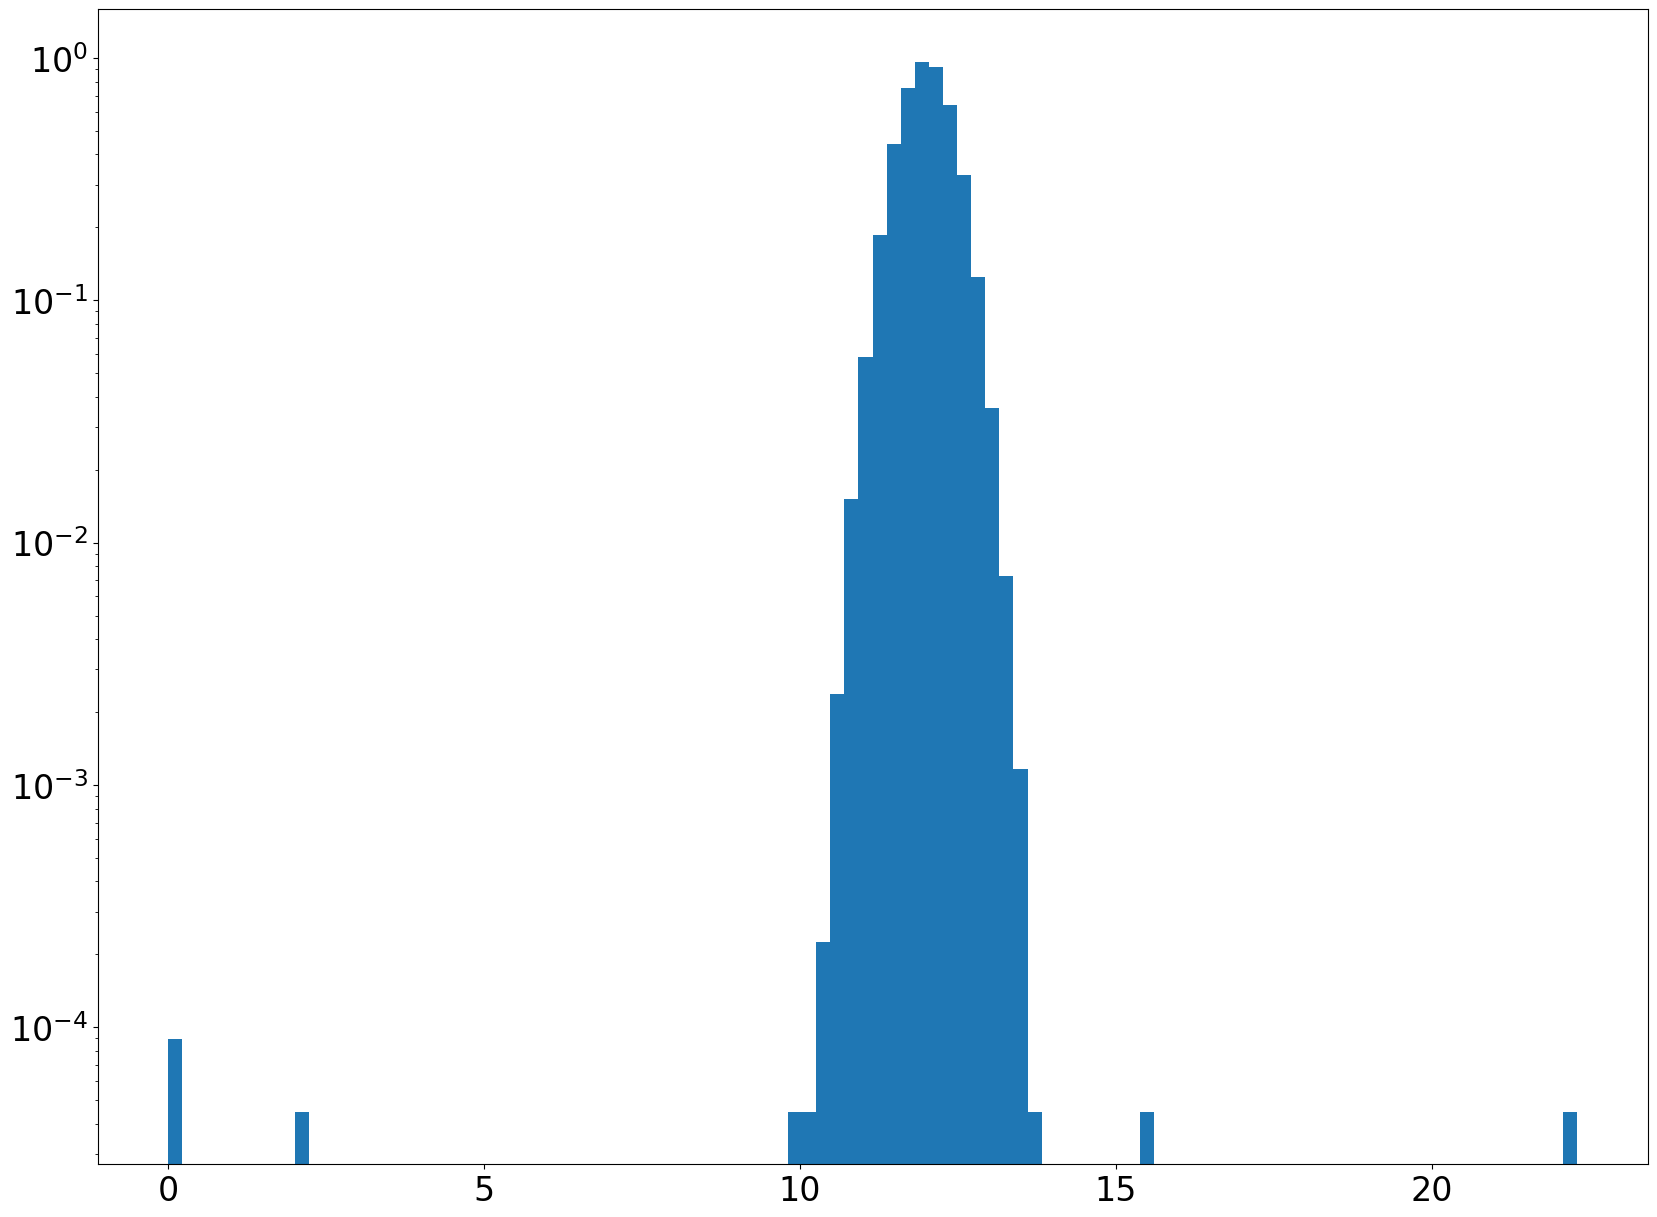

In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

#this sets the size of the plot to something useful
plt.rcParams["figure.figsize"] = (20,15)

d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.tick_params(labelsize = 24)
plt.yscale('log')
#x = np.linspace(4.95,5.05,1000)
#ax.plot(x,stats.norm.pdf(x,loc = 5., scale = 0.01),linewidth = 8,alpha = 0.7)
plt.show()

## Part A

The question we ask:

    Assuming a reading comes from the normal temperature distribution, what is the probability of observing a temperature at least as far from 12 K as this reading?

Mathematically, if

$$
H_0: T \sim \mathcal{N}(12, 0.4^2).
$$

For an observed reading $t$, what is

$$
p = P\left(|T-12| \ge |t-12| \mid H_0\right)
= 2\left[1-\Phi\left(\frac{|t-12|}{0.4}\right)\right],
$$


We choose a $3\sigma$ threshold

In [2]:
import pandas as pd

sigma = .4
k = 3  # chosen threshold in standard deviations

keep_good = np.abs(d[:-8] - 12) <= k * sigma
keep_bad = np.abs(d[-8:] - 12) <= k * sigma

pd.DataFrame(
    [[keep_good.sum(), keep_bad.sum()],
     [(~keep_good).sum(), (~keep_bad).sum()]],
    index=["Your Test Good", "Your Test Bad"],
    columns=["True T", "Bad T"]
)

,True T,Bad T
Your Test Good,99702,1
Your Test Bad,298,7


## Part B

For a threshold of $k\sigma$, increasing $k$ decreases omissions, while decreasing $k$ increases omissions.

The number of omissions is a statistically predictable quantity. For $N$ good points, on average, the number of omissions is

$$
N\times2[1-\Phi(k)].
$$

The actual number fluctuates.


## Part C

Yes. With a $3\sigma$ threshold, the bad point at $12.7 K$ is kept because it is only $1.75\sigma$ from the mean.

Decreasing the cutoff rejects more bad data but also throws out more good data. Increasing the threshold allows more bad data through. These mistakes cannot be completely avoided using temperature alone because bad datas can fall within the same range as good readings.

# Problem 2

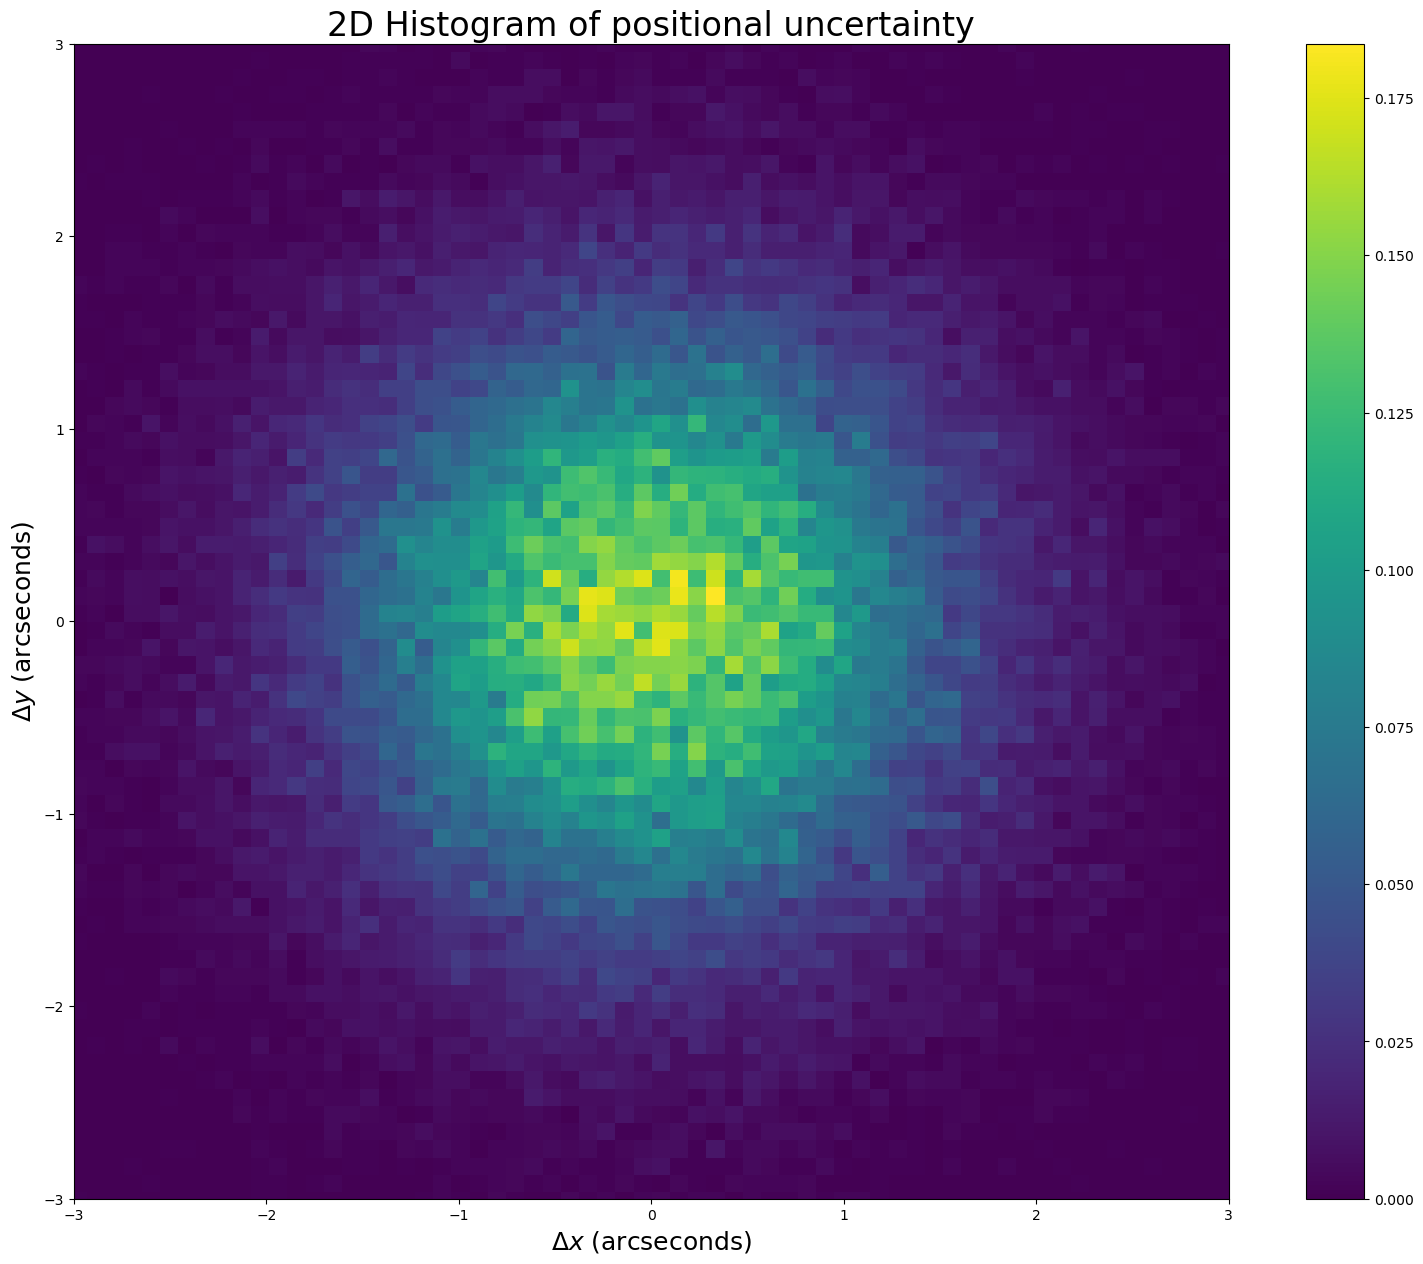

In [3]:
a = np.vstack((stats.norm.rvs( scale = 1, size = 100000), stats.norm.rvs( scale = 1, size = 100000)))
a.shape
fig, ax = plt.subplots(1, 1)
h = ax.hist2d(a[0,:],a[1,:],bins=100, density=True);
ax.set_aspect('equal', 'box')
plt.xlim([-3 , 3])
plt.ylim([-3 , 3])
plt.title("2D Histogram of positional uncertainty", fontsize = 24)
plt.ylabel(r"$\Delta y$ (arcseconds)", fontsize=18)
plt.xlabel(r"$\Delta x$ (arcseconds)", fontsize=18)
plt.colorbar(h[3], ax=ax)
plt.show()

The question is:

    If the object is actually stationary, what is the probability that measurement uncertainty alone produces an apparent displacement at least as large as the observed displacement?

Under the null hypothesis,
$$
H_0:\quad X,Y \sim N(0,1)\quad \text{independently},
$$
where displacement is measured in arcseconds. Therefore,
$$
R=\sqrt{X^2+Y^2}\sim\mathrm{Rayleigh}(1).
$$

For an observed displacement $r_{\mathrm{obs}}$, the probability is
$$
p=P(R\ge r_{\mathrm{obs}}\mid H_0)
=\int_{r_{\mathrm{obs}}}^{\infty}r e^{-r^2/2}\,dr
=e^{-r_{\mathrm{obs}}^2/2}.
$$

The $5\sigma$ distance in arcsecond is

In [4]:
p = stats.norm.sf(5)
r = stats.rayleigh.isf(p, scale=1)
print(r)

5.489079776062419


# Problem 3

The question is:

    If there were no moon shadow, what is the probability of observing a cosmic ray count at or below the measured count (6800)?

Mathematically, if

$$
H_0:\quad X\sim\operatorname{Poisson}(\lambda),
\qquad \lambda=15\times8\times60=7200.
$$

Then

$$
p=P(X\le6800\mid H_0)
=\sum_{n=0}^{6800}\frac{e^{-7200}7200^n}{n!}.
$$

Now, we compute the probability and convert it to $\sigma$.

In [5]:
p = stats.poisson.cdf(6800, mu = 7200)
z = stats.norm.isf(p)

print("p-value:", p)
print("Significance (sigma):", z)

p-value: 1.0133280183917768e-06
Significance (sigma): 4.750747965777188
